## Osteoporosis Detection Using CNN

## Project Overview

This project implements an osteoporosis detection system using MobileNetV2, a pre-trained CNN architecture with ImageNet weights. It classifies X-ray images into two categories: Normal and Osteoporosis.

## Architecture and Methodology

<b>1) Dataset Preparation:</b> Splits X-ray images into training (70%), validation (15%), and testing (15%) sets.

<b>2) Data Augmentation:</b> Applies random rotation, zoom, and contrast adjustments to improve model generalization.

<b>3) Transfer Learning:</b> Uses a pre-trained MobileNetV2 model as a feature extractor with frozen base layers.

<b>4) Classification:</b> Applies Global Average Pooling, Dropout, and a Sigmoid output layer for binary classification.

<b>5) Model Evaluation:</b> Evaluates performance using accuracy, AUC, recall, confusion matrix and classification report.

## Key Feature

Performs binary classification of X-ray images to distinguish between normal and osteoporosis cases, with the trained model saved for future predictions.

In [1]:
import os, random, shutil

random.seed(1)
SRC, DST = 'xray_all', 'xray_data'

for cls in ['normal', 'osteoporosis']:
    files = sorted(os.listdir(f'{SRC}/{cls}'))
    random.shuffle(files)
    n = len(files)
    parts = {'train': files[:int(0.7 * n)],
             'val':   files[int(0.7 * n):int(0.85 * n)],
             'test':  files[int(0.85 * n):]}
    for split, names in parts.items():
        os.makedirs(f'{DST}/{split}/{cls}', exist_ok=True)
        for f in names:
            shutil.copy(f'{SRC}/{cls}/{f}', f'{DST}/{split}/{cls}/{f}')
    print(cls, {k: len(v) for k, v in parts.items()})

normal {'train': 130, 'val': 28, 'test': 28}
osteoporosis {'train': 130, 'val': 28, 'test': 28}


In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
tfl = tf.keras.layers
tf.keras.utils.set_random_seed(1)
%matplotlib inline

In [3]:
IMG = (224, 224)

def load(folder, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        folder, label_mode='binary', image_size=IMG, batch_size=16, shuffle=shuffle, seed=1)
train_ds = load('xray_data/train', True)
val_ds = load('xray_data/val', False)
test_ds = load('xray_data/test', False)
class_names = train_ds.class_names
print(class_names)

Found 260 files belonging to 2 classes.
Found 56 files belonging to 2 classes.
Found 56 files belonging to 2 classes.
['normal', 'osteoporosis']


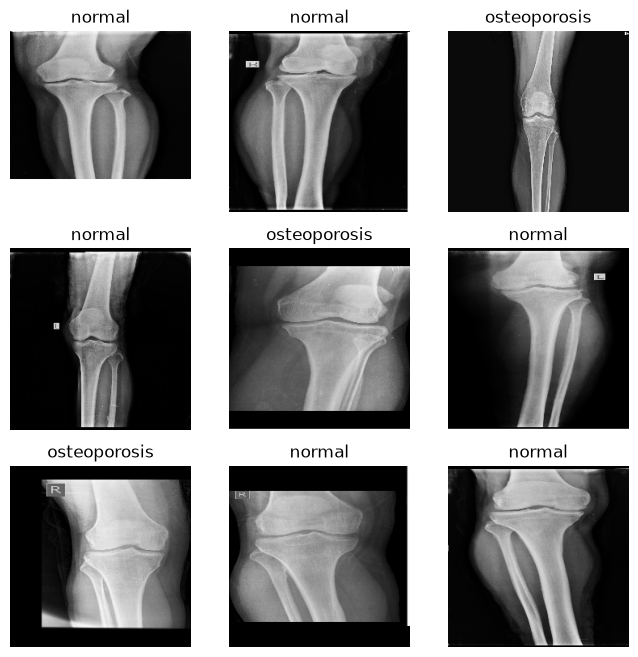

In [4]:
#to check the xrays look right

images, labels=next(iter(train_ds))
plt.figure(figsize=(8,8))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i].numpy().astype('uint8'))
    plt.title(class_names[int(labels[i][0])]);plt.axis('off')
plt.show()

In [6]:
#build the model
base = tf.keras.applications.MobileNetV2(input_shape=(224,224,3), include_top=False, weights='imagenet')
base.trainable = False

model = tf.keras.Sequential([
    tf.keras.Input(shape=(224,224,3)),
    tfl.RandomRotation(0.05),
    tfl.RandomZoom(0.1),
    tfl.RandomContrast(0.1),
    tfl.Rescaling(1./127.5, offset=-1),
    base,
    tfl.GlobalAveragePooling2D(),
    tfl.Dropout(0.3),
    tfl.Dense(1, activation='sigmoid'),
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ random_rotation_1 (RandomRotation)   │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom_1 (RandomZoom)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_contrast_1 (RandomContrast)   │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_1 (Rescaling)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.AUC(name='AUC'),
                       tf.keras.metrics.Recall(name='recall')])

In [10]:
history = model.fit(train_ds, validation_data=val_ds, epochs=20, 
                    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)])

Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 13s 702ms/step - AUC: 0.8780 - accuracy: 0.7885 - loss: 0.4264 - recall: 0.7846 - val_AUC: 0.7398 - val_accuracy: 0.7143 - val_loss: 0.5873 - val_recall: 0.8571
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 649ms/step - AUC: 0.8541 - accuracy: 0.7923 - loss: 0.4558 - recall: 0.8769 - val_AUC: 0.7423 - val_accuracy: 0.6607 - val_loss: 0.6050 - val_recall: 0.6429
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 653ms/step - AUC: 0.8932 - accuracy: 0.8192 - loss: 0.4015 - recall: 0.8846 - val_AUC: 0.7494 - val_accuracy: 0.7143 - val_loss: 0.5887 - val_recall: 0.8571
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 638ms/step - AUC: 0.8630 - accuracy: 0.8038 - loss: 0.4426 - recall: 0.8846 - val_AUC: 0.7526 - val_accuracy: 0.6786 - val_loss: 0.5963 - val_recall: 0.6786
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 12s 657ms/step - AUC: 0.8828 - accuracy: 0.8423 - loss: 0.4128 - recall: 0.9077 - val_AUC: 0.7577 - val_accuracy: 0.7143 - val_loss: 0.5923 - val_recall: 0.7143
Epoch

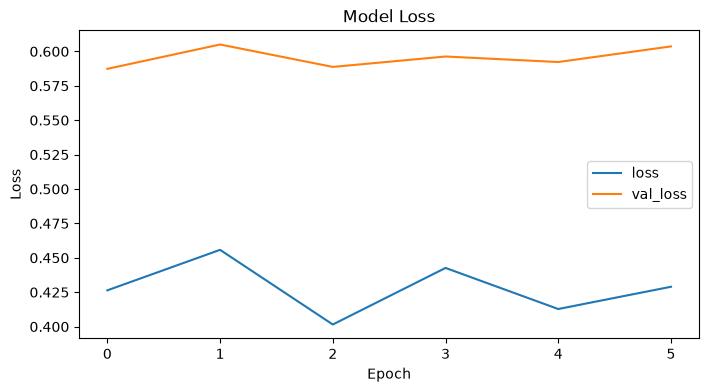

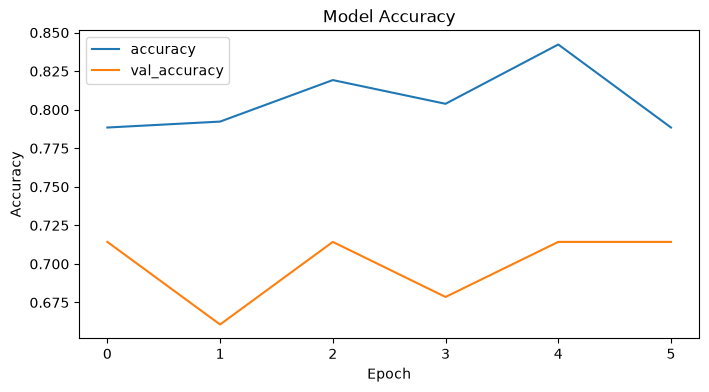

In [11]:
df = pd.DataFrame(history.history)
df[['loss', 'val_loss']].plot(title='Model Loss', figsize=(8,4)).set(xlabel='Epoch', ylabel='Loss')
df[['accuracy', 'val_accuracy']].plot(title='Model Accuracy', figsize=(8,4)).set(xlabel='Epoch', ylabel='Accuracy')
plt.show()

In [14]:
model.evaluate(test_ds)

y_true=np.concatenate([y.numpy() for _, y in test_ds]).ravel().astype(int)
y_prob=model.predict(test_ds, verbose=0).ravel()
y_pred=(y_prob > 0.5).astype(int)

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=class_names))

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 440ms/step - AUC: 0.6633 - accuracy: 0.6429 - loss: 0.7296 - recall: 0.8214
[[13 15]
 [ 5 23]]
              precision    recall  f1-score   support

      normal       0.72      0.46      0.57        28
osteoporosis       0.61      0.82      0.70        28

    accuracy                           0.64        56
   macro avg       0.66      0.64      0.63        56
weighted avg       0.66      0.64      0.63        56



In [15]:
#save the model
model.save("osteoporosis_cnn.keras")

P(osteoporosis) = 0.707 -> osteoporosis


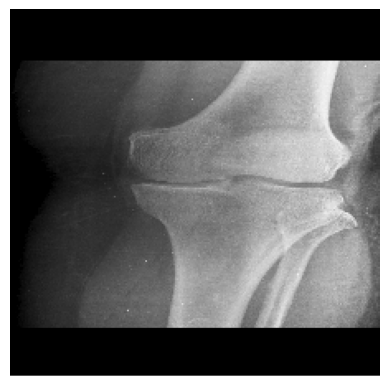

In [18]:
path = 'test_2.png'
img = tf.keras.utils.load_img(path, target_size=(224,224))
x = tf.keras.utils.img_to_array(img)[np.newaxis]
p = float(model.predict(x, verbose=0)[0][0])
print(f'P(osteoporosis) = {p:.3f} ->', 'osteoporosis' if p > 0.5 else'normal')
plt.imshow(img); plt.axis('off'); plt.show()

In [ ]:
# to run the model
model = tf.keras.models.load_model('osteoporosis_cnn.keras')